In [1]:
# The purpose of this notebook is to scale the training data, just the 
# inout feature columns, the targets we won't scale

In [2]:
# import the data

from pathlib import Path
import pandas as pd
import numpy as np

# Load the compiled data
project_root = Path.cwd().resolve().parent if 'notebooks' in str(Path.cwd()) else Path.cwd().resolve()
excel_path = project_root / 'data' / 'raw' / 'Compiled Data.xlsx'

df = pd.read_excel(excel_path)

formula_cols = ["TEM", "Joncryl", "NC513", "PEG-DE", "NGDE"]
measured_target_cols = [
    "Avg_Density_g_cm3",
    "Dry Strength Mean",
    "Wet Strength Mean",
]
measured_se_cols = [
    "Avg_Density SE",
    "Dry Strength SE",
    "Wet Strength SE",
]

# Keep each target beside its standard error column
measured_cols = [
    col
    for target, se in zip(measured_target_cols, measured_se_cols)
    for col in (target, se)
]
df = df.loc[:, formula_cols + measured_cols]

df["std_Avg_Density_g_cm3"] = df["Avg_Density SE"] * np.sqrt(3)
df["std_Dry Strength Mean"] = df["Dry Strength SE"] * np.sqrt(3)
df["std_Wet Strength Mean"] = df["Wet Strength SE"] * np.sqrt(3)

print(df.head())

   TEM  Joncryl  NC513  PEG-DE  NGDE  Avg_Density_g_cm3  Avg_Density SE  \
0    8      NaN    NaN     NaN   NaN           0.192000        0.002667   
1    8      0.7    NaN     NaN   NaN           0.195000        0.007263   
2    8      1.0    NaN     NaN   NaN           0.159000        0.005033   
3    8      1.5    NaN     NaN   NaN           0.159933        0.004410   
4    8      2.0    NaN     NaN   NaN           0.201000        0.008817   

   Dry Strength Mean  Dry Strength SE  Wet Strength Mean  Wet Strength SE  \
0          53.674733         1.008133          23.680000         0.200000   
1          68.863717         4.243165          24.258481         1.187076   
2          50.405845         2.550662          21.329450         1.916881   
3          54.717605         0.566776          20.183592         0.276639   
4          85.787785         6.781653          27.585357         2.274881   

   std_Avg_Density_g_cm3  std_Dry Strength Mean  std_Wet Strength Mean  
0            

In [3]:
from sklearn.preprocessing import StandardScaler

# initialize the scaler
scaler = StandardScaler()

train = df[formula_cols]  # select only the input feature columns for scaling

# fit and transform all columns
train_scaled_array = scaler.fit_transform(train)

# create a new scaled dataframe with the same column names
scaled_df = pd.DataFrame(train_scaled_array, columns=train.columns)

# Combine scaled formula columns with unscaled target columns
result_df = pd.concat([scaled_df, df.drop(columns=formula_cols)], axis=1)

# save the scaled data to csv
result_df.to_csv('../data/clean/train_scaled.csv', index=False)

print("Scaled data shape:", result_df.shape)
print("\nFirst few rows of scaled data:")
print(result_df.head())
print("\nScaled data saved to: ../data/clean/train_scaled.csv")

print(scaler.var_)

Scaled data shape: (25, 14)

First few rows of scaled data:
   TEM   Joncryl  NC513  PEG-DE  NGDE  Avg_Density_g_cm3  Avg_Density SE  \
0  0.5       NaN    NaN     NaN   NaN           0.192000        0.002667   
1  0.5 -0.959381    NaN     NaN   NaN           0.195000        0.007263   
2  0.5 -0.520342    NaN     NaN   NaN           0.159000        0.005033   
3  0.5  0.211389    NaN     NaN   NaN           0.159933        0.004410   
4  0.5  0.943121    NaN     NaN   NaN           0.201000        0.008817   

   Dry Strength Mean  Dry Strength SE  Wet Strength Mean  Wet Strength SE  \
0          53.674733         1.008133          23.680000         0.200000   
1          68.863717         4.243165          24.258481         1.187076   
2          50.405845         2.550662          21.329450         1.916881   
3          54.717605         0.566776          20.183592         0.276639   
4          85.787785         6.781653          27.585357         2.274881   

   std_Avg_Density_g

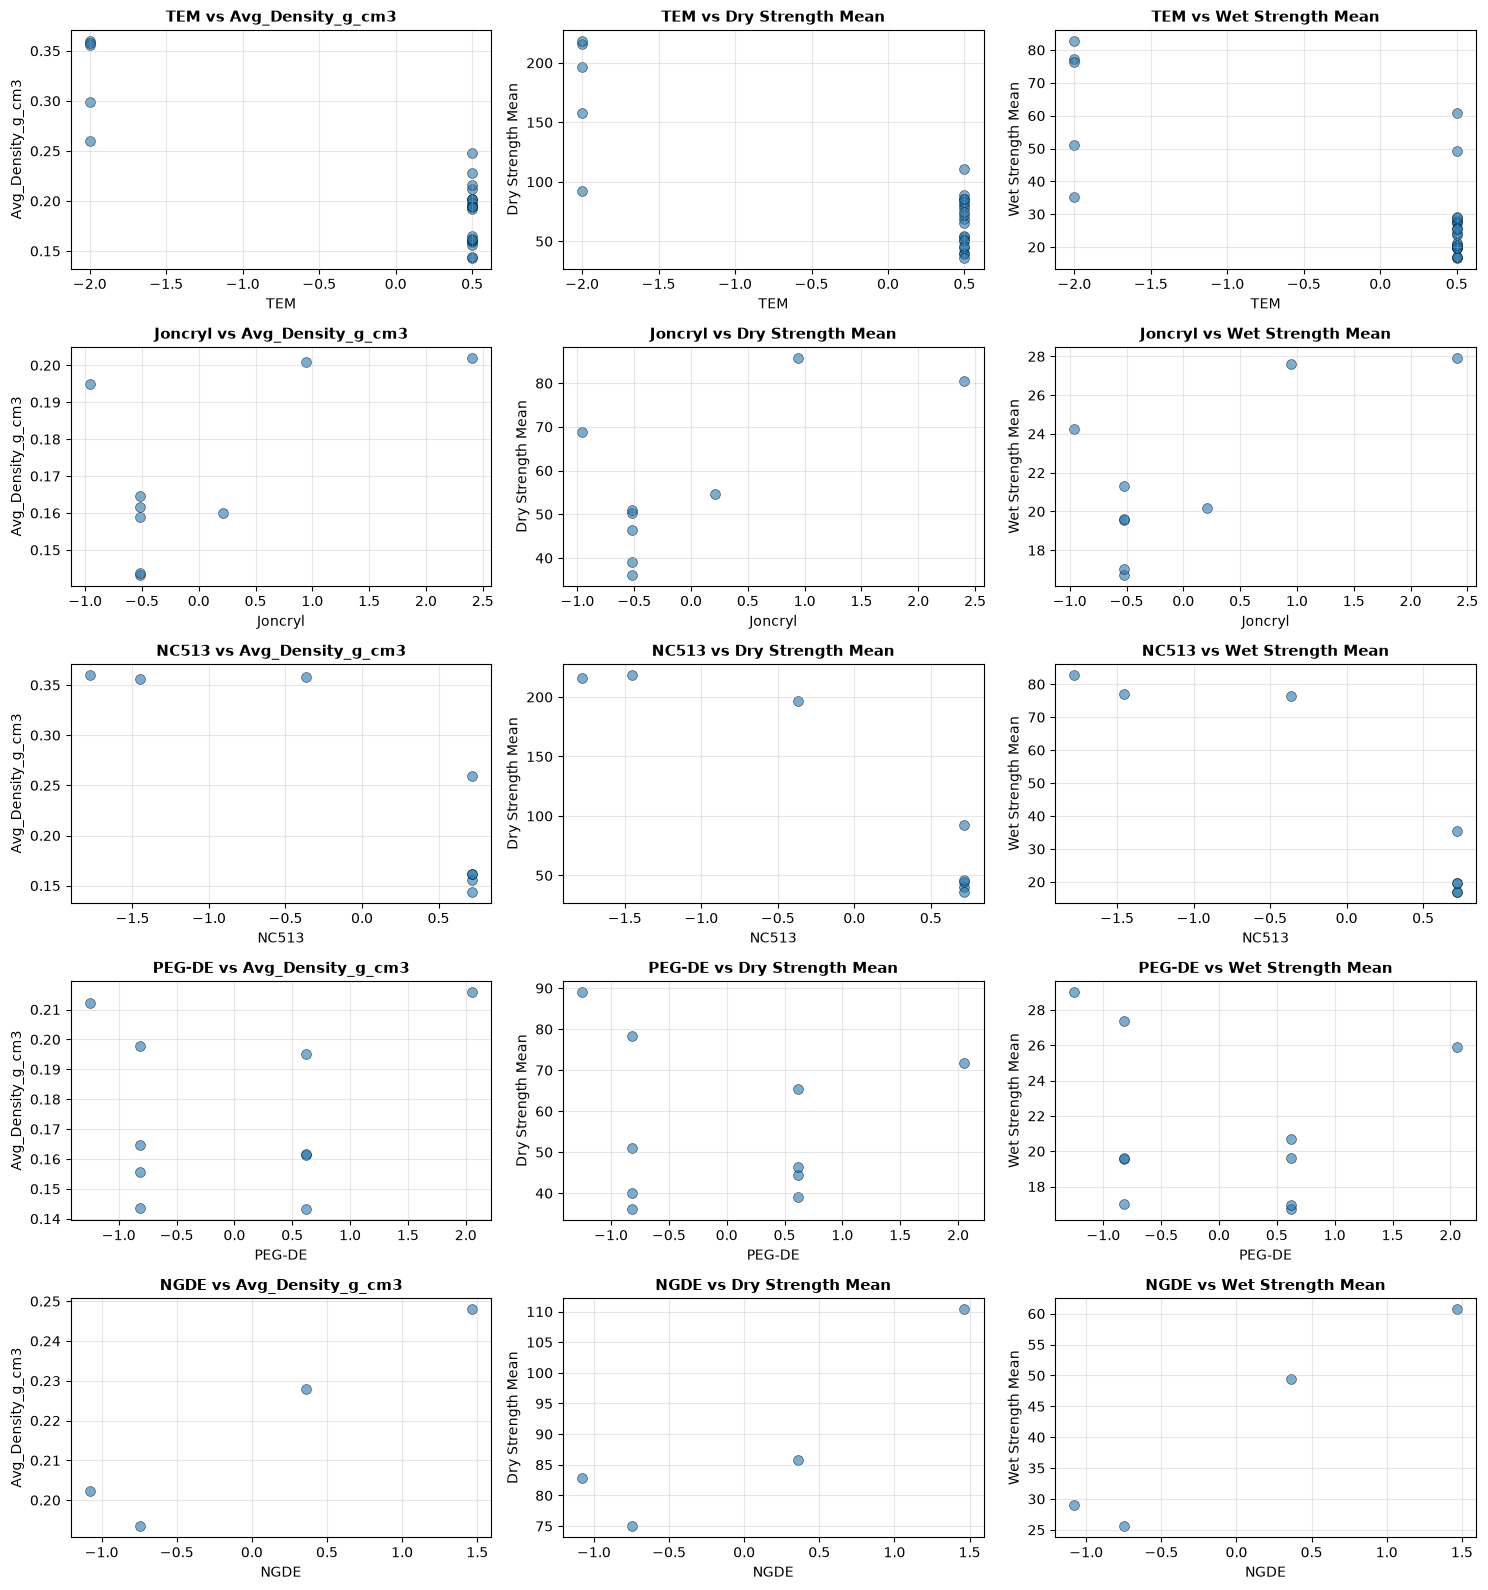

In [4]:
# look at formula_cols = ["TEM", "Joncryl", "NC513", "PEG-DE", "NGDE"] vs density, dry and wet strength

import matplotlib.pyplot as plt
import numpy as np

formula_cols = ["TEM", "Joncryl", "NC513", "PEG-DE", "NGDE"]
measured_target_cols = [
    "Avg_Density_g_cm3",
    "Dry Strength Mean",
    "Wet Strength Mean",
]

# Create a 5x3 grid of subplots (5 formula cols, 3 measured targets)
fig, axes = plt.subplots(5, 3, figsize=(15, 16))

for i, formula_col in enumerate(formula_cols):
    for j, target_col in enumerate(measured_target_cols):
        ax = axes[i, j]
        
        # Create scatter plot
        ax.scatter(result_df[formula_col], result_df[target_col], alpha=0.6, s=50, edgecolors='k', linewidth=0.5)
        
        # Add labels and title
        ax.set_xlabel(formula_col, fontsize=10)
        ax.set_ylabel(target_col, fontsize=10)
        ax.set_title(f'{formula_col} vs {target_col}', fontsize=11, fontweight='bold')
        
        # Add grid
        ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [ ]:
# import the data with the replicates for wet strength

from pathlib import Path
import pandas as pd
import numpy as np

# Load the compiled data
project_root = Path.cwd().resolve().parent if 'notebooks' in str(Path.cwd()) else Path.cwd().resolve()
excel_path = project_root / 'data' / 'raw' / 'Data - replicates_filled.xlsx'

df = pd.read_excel(excel_path)

Dry_strength_cols = ['Dry Strength 1', 'Dry Strength 2', 'Dry Strength 3']

print(df.head(10))

   TEM  Joncryl  NC513  PEG-DE  NGDE  Dry Strength 1  Dry Strength 2  \
0    8      NaN    NaN     NaN   NaN       51.762782       55.185081   
1    8      0.7    NaN     NaN   NaN       77.314090       65.314367   
2    8      1.0    NaN     NaN   NaN       54.973140       50.090062   
3    8      1.5    NaN     NaN   NaN       53.929339       55.817204   
4    8      2.0    NaN     NaN   NaN       92.299000       68.405772   
5    8      3.0    NaN     NaN   NaN       74.539606       86.574932   
6    5      NaN    NaN     NaN   NaN      157.090041      152.861264   
7    5      NaN    0.7     NaN   NaN      220.834385      202.599118   
8    5      NaN    1.0     NaN   NaN      207.075931      223.045009   
9    5      NaN    2.0     NaN   NaN      187.377811      197.407723   

   Dry Strength 3  Dry Strength Mean  Dry Strength SE  Wet Strength 1  \
0       54.076336          53.674733         1.008133             NaN   
1       63.962694          68.863717         4.243165       2

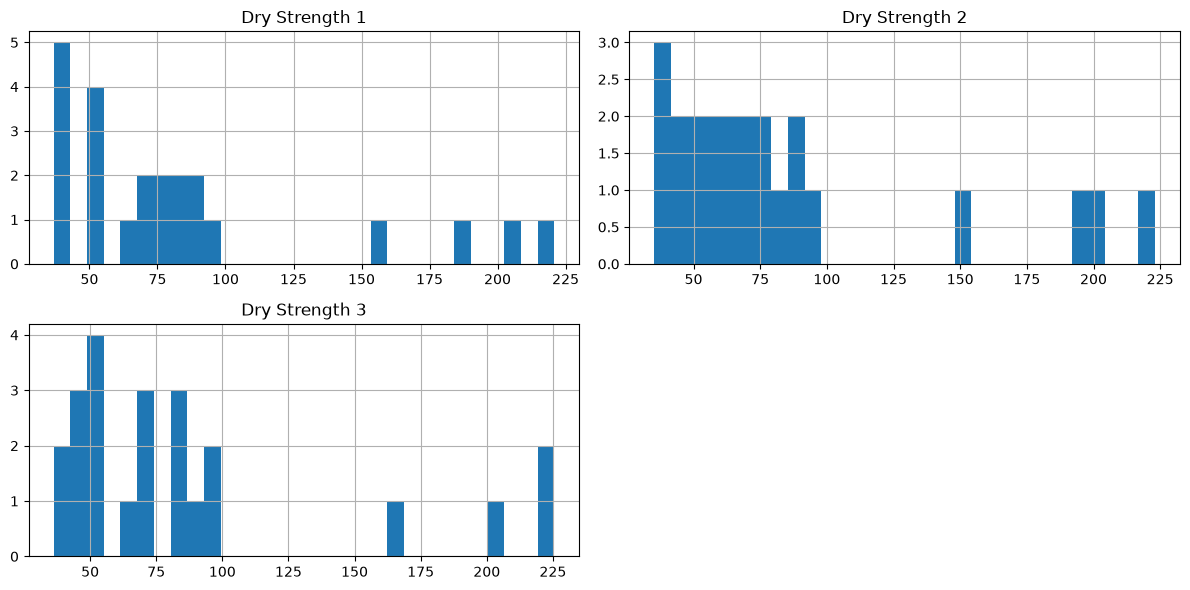

Scaled data shape: (25, 4)

First few rows of scaled data:
    Dry Strength 1  Dry Strength 2  Dry Strength 3  Variance
0        -0.654719       -0.556178       -0.611894  0.002441
1        -0.171142       -0.367608       -0.437274  0.019046
2        -0.593961       -0.651029       -0.751818  0.006389
3        -0.613716       -0.544410       -0.606066  0.001444
4         0.112459       -0.310057        0.140225  0.063674
5        -0.223651        0.028186       -0.145325  0.016611
6         1.338678        1.262196        1.312495  0.001511
7         2.545088        2.188133        2.398861  0.032201
8         2.284699        2.568760        2.416098  0.020210
9         1.911897        2.091488        2.040371  0.008562
10        0.074203        0.143692        0.095797  0.001265
11       -0.656262       -0.666527       -0.647758  0.000088
12       -0.924829       -0.896805       -0.755783  0.008208
13       -0.863839       -0.896374       -0.868284  0.000311
14       -0.830645       -

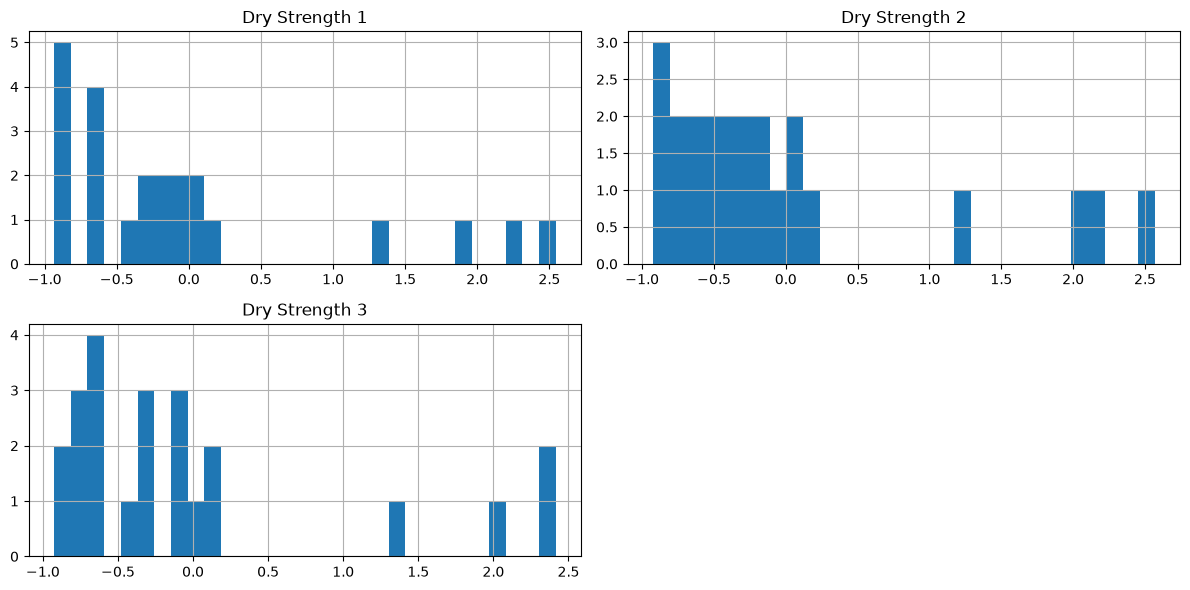

In [11]:
# standardize the Dry Strength values using standard scaler

from sklearn.preprocessing import StandardScaler

# initialize the scaler
scaler = StandardScaler()

train = df[Dry_strength_cols]  # select only the input feature columns for scaling

# histogram of dry_strength_columns
train[Dry_strength_cols].hist(figsize=(12, 6), bins=30)
plt.tight_layout()
plt.show()

# fit and transform all columns
train_scaled_array = scaler.fit_transform(train)

# create a new scaled dataframe with the same column names
scaled_df = pd.DataFrame(train_scaled_array, columns=train.columns)

# Calculate variance across the 3 replicates for each row
scaled_df['Variance'] = scaled_df[['Dry Strength 1', 'Dry Strength 2', 'Dry Strength 3']].var(axis=1)

# save the scaled data to csv
scaled_df.to_csv('../data/clean/Dry_strength_Replicates_scaled.csv', index=False)

print("Scaled data shape:", scaled_df.shape)
print("\nFirst few rows of scaled data:")
print(scaled_df.head(25))
print("\nScaled data saved to: ../data/clean/Dry_strength_Replicates_scaled.csv")

# histogram of scaled_df
scaled_df[Dry_strength_cols].hist(figsize=(12, 6), bins=30)
plt.tight_layout()
plt.show()


In [12]:
# calculate the average variance of scaled_df['Variance']

average_variance = scaled_df['Variance'].mean()
print("Average variance of scaled_df['Variance']:", average_variance)

Average variance of scaled_df['Variance']: 0.010558401323694249
